In [19]:
%pip install lxml
%pip install kagglehub
%pip install ultralytics
%pip install imagehash


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



  Obtaining dependency information for imagehash from https://files.pythonhosted.org/packages/31/2c/5f0903a53a62029875aaa3884c38070cc388248a2c1b9aa935632669e5a7/ImageHash-4.3.2-py2.py3-none-any.whl.metadata
  Obtaining dependency information for PyWavelets from https://files.pythonhosted.org/packages/5b/4c/6490c47aefdc3d210db3e071a9592ca453d01c55a1338682da970792bfad/pywavelets-1.10.0-cp312-cp312-win_amd64.whl.metadata
   ---------------------------------------- 0.0/296.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/296.7 kB ? eta -:--:--
   - -------------------------------------- 10.2/296.7 kB ? eta -:--:--
   - -------------------------------------- 10.2/296.7 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/296.7 kB 217.9 kB/s eta 0:00:02
   ----- --------------------------------- 41.0/296.7 kB 196.9 kB/s eta 0:00:02
   --------- ----------------------------- 71.7/296.7 kB 302.7 kB/s eta 0:00:01
   ------------ -------------------------- 92.2/296


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("andrewmvd/road-sign-detection")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Kamila\.cache\kagglehub\datasets\andrewmvd\road-sign-detection\versions\1


In [21]:
import os
import io
import shutil
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from glob import glob
from PIL import Image
from lxml import etree
from tqdm import tqdm
from pathlib import Path
import xml.etree.ElementTree as ET
import random
from ultralytics import YOLO
from collections import Counter
import hashlib
import imagehash

In [13]:
print(os.listdir(path))

['annotations', 'images']


In [14]:
SEED = 42
class_dict = {"stop": 0, "speedlimit": 1, "crosswalk": 2, "trafficlight": 3}
SRC = Path(path)
OUT = Path("data/yolo")
def voc_to_yolo(xml_path):
    root = ET.parse(xml_path).getroot()
    w = int(root.find("size/width").text)
    h = int(root.find("size/height").text)
    lines = []
    for obj in root.findall("object"):
        cls = class_dict[obj.find("name").text.strip()]
        b = obj.find("bndbox")
        x1, y1 = float(b.find("xmin").text), float(b.find("ymin").text)
        x2, y2 = float(b.find("xmax").text), float(b.find("ymax").text)
        lines.append(f"{cls} {(x1+x2)/2/w:.6f} {(y1+y2)/2/h:.6f} {(x2-x1)/w:.6f} {(y2-y1)/h:.6f}")
    return lines

def split_and_convert(train_size=0.7, val_size=0.15, seed=SEED):
    stems = sorted(p.stem for p in (SRC / "annotations").glob("*.xml"))
    random.Random(seed).shuffle(stems)
    n = len(stems)
    t, v = int(n * train_size), int(n * (train_size + val_size))
    splits = {"train": stems[:t], "val": stems[t:v], "test": stems[v:]}
    for split, names in splits.items():
        (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
        (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)
        for s in names:
            shutil.copy(SRC / "images" / f"{s}.png", OUT / "images" / split / f"{s}.png")
            (OUT / "labels" / split / f"{s}.txt").write_text("\n".join(voc_to_yolo(SRC / "annotations" / f"{s}.xml")))
        print(split, len(names), "images")

split_and_convert()

train 613 images
val 132 images
test 132 images


In [15]:
names = {v: k for k, v in class_dict.items()}
yaml_text = f"path: {OUT.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
yaml_text += "".join(f"  {i}: {names[i]}\n" for i in range(len(names)))
(OUT / "data.yaml").write_text(yaml_text)
print(yaml_text)

path: C:/Users/Kamila/Desktop/kbtu/4year/fall/DL/road-sign-detector/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: stop
  1: speedlimit
  2: crosswalk
  3: trafficlight



In [16]:
for split in ["train", "val", "test"]:
    c, n_img = Counter(), 0
    for f in (OUT / "labels" / split).glob("*.txt"):
        n_img += 1
        for line in f.read_text().splitlines():
            if line.strip():
                c[names[int(line.split()[0])]] += 1
    print(split, n_img, "images,", sum(c.values()), "objects", dict(c))

train 613 images, 877 objects {'trafficlight': 129, 'speedlimit': 545, 'crosswalk': 147, 'stop': 56}
val 132 images, 174 objects {'trafficlight': 15, 'speedlimit': 114, 'crosswalk': 24, 'stop': 21}
test 132 images, 193 objects {'speedlimit': 124, 'crosswalk': 29, 'trafficlight': 26, 'stop': 14}


In [18]:
problems, md5 = [], {}
for split in ["train", "val", "test"]:
    for img in (OUT / "images" / split).glob("*.png"):
        lab = OUT / "labels" / split / f"{img.stem}.txt"
        if not lab.exists():
            problems.append((img.name, "no label file")); continue
        lines = [l.split() for l in lab.read_text().splitlines() if l.strip()]
        if not lines:
            problems.append((img.name, "empty label"))
        for parts in lines:
            c, cx, cy, w, h = int(parts[0]), *map(float, parts[1:])
            if not (0 <= c < 4 and w > 0 and h > 0
                    and cx - w/2 >= -1e-3 and cx + w/2 <= 1 + 1e-3
                    and cy - h/2 >= -1e-3 and cy + h/2 <= 1 + 1e-3):
                problems.append((img.name, f"bad box {parts}"))
        md5.setdefault(hashlib.md5(img.read_bytes()).hexdigest(), []).append((split, img.name))

print("problems:", problems or "none")
print("exact duplicates:", [v for v in md5.values() if len(v) > 1] or "none")

problems: none
exact duplicates: [[('train', 'road145.png'), ('train', 'road147.png')], [('train', 'road42.png'), ('train', 'road48.png')]]


In [22]:
hashes = [(s, p.name, imagehash.phash(Image.open(p)))
          for s in ["train", "val", "test"] for p in (OUT / "images" / s).glob("*.png")]
pairs = [(a[:2], b[:2], a[2] - b[2]) for i, a in enumerate(hashes)
         for b in hashes[i+1:] if a[0] != b[0] and a[2] - b[2] <= 4]
print(len(pairs), "near-duplicate pairs across different splits")
print(pairs[:10])

0 near-duplicate pairs across different splits
[]


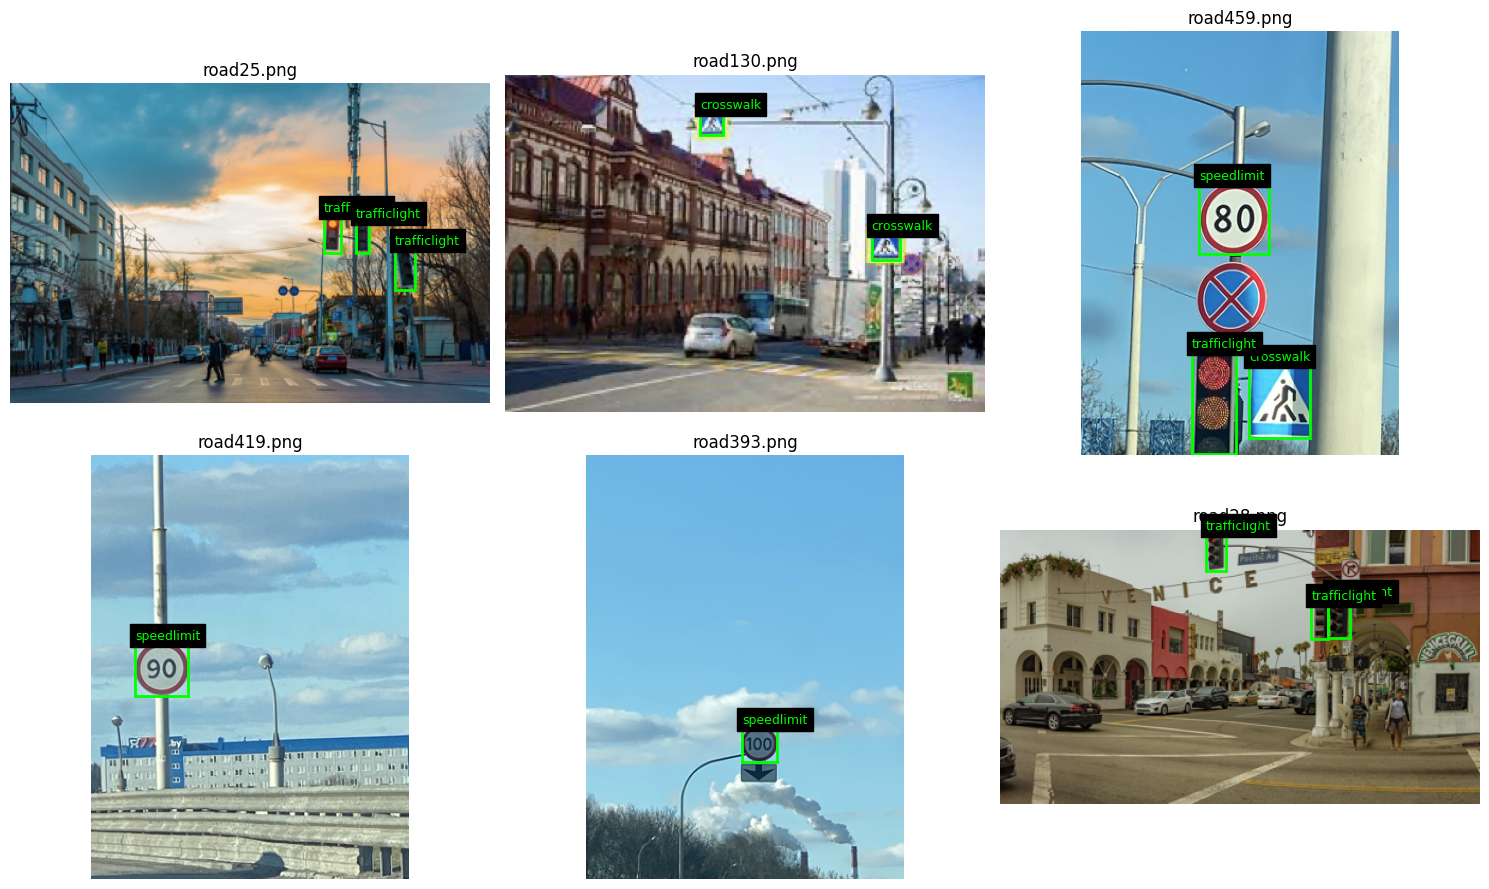

In [23]:
def show_gt(split="train", k=6):
    imgs = sorted((OUT / "images" / split).glob("*.png"))
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, p in zip(axes.ravel(), random.Random(SEED).sample(imgs, k)):
        im = Image.open(p); W, H = im.size
        ax.imshow(im); ax.axis("off"); ax.set_title(p.name)
        for l in (OUT / "labels" / split / f"{p.stem}.txt").read_text().splitlines():
            parts = l.split()
            c, (cx, cy, w, h) = int(parts[0]), map(float, parts[1:])
            x, y = (cx - w/2) * W, (cy - h/2) * H
            ax.add_patch(patches.Rectangle((x, y), w*W, h*H, fill=False, edgecolor="lime", linewidth=2))
            ax.text(x, y - 3, names[c], color="lime", backgroundcolor="black", fontsize=9)
    plt.tight_layout()
    Path("results").mkdir(exist_ok=True)
    plt.savefig("results/gt_examples.png", dpi=120)
    plt.show()

show_gt()